# Week 4 - Logistic Regression and Feature Scaling
## Dataset: FEMA NFIP Claims

This week covers logistic regression and feature scaling. Logistic regression predicts the probability of a yes or no outcome, so I turned the NFIP payout into one. Did a 2017 claim pay more than $50,000 on the building? That cutoff sits close to the median payout, so the two classes come out close to balanced, with 53% of claims above it.

The model starts from what the lesson calls LINEXP, the linear combination $\text{LINEXP} = \beta_0 + \sum_i \beta_i X_i$. Instead of using LINEXP as the prediction, logistic regression treats it as the log-odds of the outcome and passes it through the logistic function $p = \dfrac{1}{1 + e^{-\text{LINEXP}}}$, which always lands between 0 and 1. The coefficients are chosen to minimize cross-entropy loss, and adding an L1 or L2 penalty to that loss gives the Lasso and Ridge versions from Week 2.

Most of this notebook works through the practical issues the lesson raises. I look at what scaling does to the solver and to the penalty, how outliers in water depth distort the fit, what happens to the coefficients when features overlap, and whether 101,042 claims from the same few storms really count as independent samples. Unlike the Week 2 notebook, which predicted payout from the damage amount, every damage and payout field is left out here, so the model has to work from information about the building, the policy, and the flood.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, GroupShuffleSplit, GroupKFold,
                                     GridSearchCV, validation_curve)
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, RobustScaler,
                                   SplineTransformer, OneHotEncoder)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score,
                             log_loss, ConfusionMatrixDisplay)
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=FutureWarning)


def fit_quietly(model, X, y):
    """Fit a model and report whether the solver hit its iteration limit."""
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always', ConvergenceWarning)
        t0 = time.time()
        model.fit(X, y)
        seconds = time.time() - t0
    hit_limit = any(issubclass(w.category, ConvergenceWarning) for w in caught)
    return seconds, hit_limit


def scores(name, y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {'Model': name,
            'Accuracy': accuracy_score(y_true, pred),
            'Balanced acc.': balanced_accuracy_score(y_true, pred),
            'F1': f1_score(y_true, pred),
            'Log loss': log_loss(y_true, np.clip(prob, 1e-6, 1 - 1e-6)),
            'ROC-AUC': roc_auc_score(y_true, prob)}

df_raw = pd.read_csv('FimaNfipClaimsV2.csv', low_memory=False)
df = df_raw[(df_raw['yearOfLoss'] == 2017) & (df_raw['amountPaidOnBuildingClaim'] >= 0)].copy()
print('2017 claims with a non-negative building payout:', len(df))

2017 claims with a non-negative building payout: 113398


### Target and features

The target is `largeClaim`, which equals 1 when the building payout is above $50,000. Claims with negative payouts (adjustments and recoveries) are dropped.

The features are recorded water depth in the building, building replacement cost, building coverage, number of floors, construction year, latitude and longitude, and five yes or no indicators. Those are whether the building is elevated, whether it is a primary residence, whether it was built after the community's flood map took effect (post-FIRM), and whether the rated flood zone is an A zone or a V zone, with X and everything else as the baseline. Rows missing any of these are dropped, along with a few construction years outside 1800 to 2017, which I treat as entry errors.

The table printed by the next cell shows why this week's topic matters for this data. The raw features sit on wildly different scales. Replacement cost has a standard deviation of about $7.4 million and a maximum near $967 million, construction year sits around 1978 with a standard deviation of 19, and the indicators are all 0 or 1. Water depth runs from -36 to 610 even though its median is 1, so it has outliers on both ends.

In [2]:
df['constructionYear'] = pd.to_datetime(df['originalConstructionDate'], errors='coerce').dt.year
zone_letter = df['ratedFloodZone'].astype(str).str.upper().str[0]
df['zoneA'] = (zone_letter == 'A').astype(int)
df['zoneV'] = (zone_letter == 'V').astype(int)

raw_features = ['waterDepth', 'buildingReplacementCost', 'totalBuildingInsuranceCoverage',
                'numberOfFloorsInTheInsuredBuilding', 'elevatedBuildingIndicator', 'primaryResidenceIndicator',
                'postFIRMConstructionIndicator', 'constructionYear', 'latitude', 'longitude', 'zoneA', 'zoneV']
data = df.dropna(subset=raw_features).copy()
data = data[data['constructionYear'].between(1800, 2017)].reset_index(drop=True)
data['largeClaim'] = (data['amountPaidOnBuildingClaim'] > 50000).astype(int)

data['logReplacementCost'] = np.log10(data['buildingReplacementCost'].clip(lower=1))
data['logCoverage'] = np.log10(data['totalBuildingInsuranceCoverage'].clip(lower=1))
# Beyond about 15 the share of large claims is flat and claims are sparse, so depth is capped there
data['depthClipped'] = data['waterDepth'].clip(-2, 15)

continuous = ['logReplacementCost', 'logCoverage', 'numberOfFloorsInTheInsuredBuilding',
              'constructionYear', 'latitude', 'longitude']
binary = ['elevatedBuildingIndicator', 'primaryResidenceIndicator', 'postFIRMConstructionIndicator', 'zoneA', 'zoneV']
log_features = ['waterDepth'] + continuous + binary

print('Rows used:', len(data), '| share of claims over $50,000:', round(data['largeClaim'].mean(), 3))
print()
print('How different the raw feature scales are:')
data[raw_features].agg(['mean', 'std', 'min', 'max']).T.apply(lambda c: c.map(lambda v: f'{v:,.2f}'))

Rows used: 101042 | share of claims over $50,000: 0.532

How different the raw feature scales are:


,mean,std,min,max
waterDepth,2.64,12.10,-36.00,610.00
buildingReplacementCost,"633,404.61","7,439,770.38",0.00,"966,743,634.00"
totalBuildingInsuranceCoverage,"285,432.73","1,654,593.22",0.00,"122,766,900.00"
numberOfFloorsInTheInsuredBuilding,1.47,0.74,1.00,6.00
elevatedBuildingIndicator,0.17,0.37,0.00,1.00
primaryResidenceIndicator,0.76,0.43,0.00,1.00
postFIRMConstructionIndicator,0.46,0.50,0.00,1.00
constructionYear,"1,977.66",19.23,"1,800.00","2,017.00"
latitude,29.92,3.11,13.40,59.60
longitude,-92.00,7.18,-159.50,144.60


In [3]:
y = data['largeClaim'].values
train_idx, test_idx = train_test_split(np.arange(len(y)), test_size=0.25, stratify=y, random_state=0)
train, test = data.iloc[train_idx], data.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
print('Training claims:', len(y_train), '| Test claims:', len(y_test))

Training claims:

 75781 | Test claims: 25261


### Feature scaling and the solver

The lesson gives two reasons to scale features before fitting a logistic regression. The first is speed. A gradient-based solver adjusts each coefficient according to how much it moves the loss, and a feature measured in large units moves the loss a lot, so the solver keeps overcorrecting in that direction while barely touching the others. The second is fairness of the penalty, which I come back to after the results.

To test both, I fit the same logistic regression with six setups. Two use the raw features, once unscaled and once standardized. The other four replace replacement cost and coverage with their base-10 logs and then apply no scaling, standardization (mean 0, standard deviation 1), min-max scaling (every feature squeezed into the range 0 to 1), or robust scaling (centered on the median and divided by the interquartile range). Each setup runs at C = 1, a light penalty, and at C = 0.001, a strong one. In scikit-learn, C is the inverse of the lesson's $\lambda$, so a smaller C means more regularization. The solver is L-BFGS, scikit-learn's default. It uses gradients the way gradient descent does but also estimates the curvature of the loss, so it should be less sensitive to scale than plain gradient descent. The iteration limit is 1,000.

                     Setup     C  Solver iterations  Hit iteration limit  Fit seconds  Test log loss  Test ROC-AUC
  Raw features, no scaling 1.000                160                False         0.61         0.6475        0.6509
Raw features, standardized 1.000                 12                False         0.07         0.6107        0.7263
     Log costs, no scaling 1.000               1000                 True         3.48         0.5801        0.7757
   Log costs, standardized 1.000                  9                False         0.06         0.5771        0.7789
        Log costs, min-max 1.000                 52                False         0.21         0.5782        0.7778
         Log costs, robust 1.000                 60                False         0.23         0.5771        0.7789
  Raw features, no scaling 0.001                237                False         0.84         0.6280        0.6879
Raw features, standardized 0.001                 10                False        

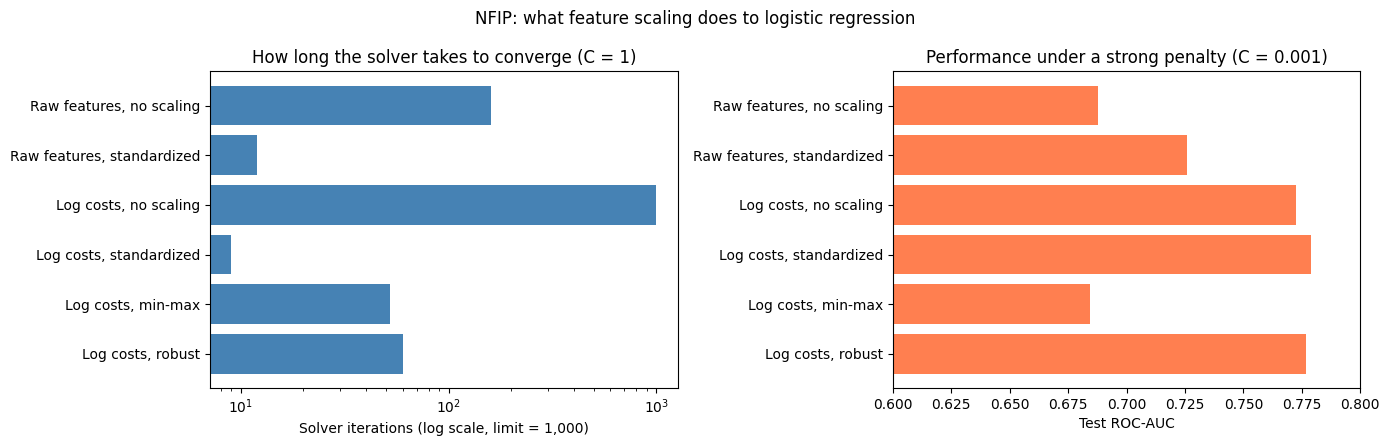

In [4]:
configs = [
    ('Raw features, no scaling', raw_features, None),
    ('Raw features, standardized', raw_features, StandardScaler),
    ('Log costs, no scaling', log_features, None),
    ('Log costs, standardized', log_features, StandardScaler),
    ('Log costs, min-max', log_features, MinMaxScaler),
    ('Log costs, robust', log_features, RobustScaler),
]
rows = []
for C in [1.0, 0.001]:
    for name, cols, scaler in configs:
        steps = ([scaler()] if scaler else []) + [LogisticRegression(C=C, max_iter=1000)]
        model = make_pipeline(*steps)
        seconds, hit_limit = fit_quietly(model, train[cols], y_train)
        prob = model.predict_proba(test[cols])[:, 1]
        rows.append({'Setup': name, 'C': C, 'Solver iterations': model[-1].n_iter_[0],
                     'Hit iteration limit': hit_limit, 'Fit seconds': round(seconds, 2),
                     'Test log loss': round(log_loss(y_test, prob), 4),
                     'Test ROC-AUC': round(roc_auc_score(y_test, prob), 4)})
scaling_results = pd.DataFrame(rows)
print(scaling_results.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
weak = scaling_results[scaling_results['C'] == 1.0]
strong = scaling_results[scaling_results['C'] == 0.001]
axes[0].barh(weak['Setup'], weak['Solver iterations'], color='steelblue')
axes[0].set_xscale('log')
axes[0].set_xlabel('Solver iterations (log scale, limit = 1,000)')
axes[0].set_title('How long the solver takes to converge (C = 1)')
axes[0].invert_yaxis()
axes[1].barh(strong['Setup'], strong['Test ROC-AUC'], color='coral')
axes[1].set_xlim(0.6, 0.8)
axes[1].set_xlabel('Test ROC-AUC')
axes[1].set_title('Performance under a strong penalty (C = 0.001)')
axes[1].invert_yaxis()
fig.suptitle('NFIP: what feature scaling does to logistic regression')
plt.tight_layout()
plt.show()

The left panel shows the speed problem. With the log features left unscaled, the solver used all 1,000 iterations without converging and took 3.5 seconds. After standardizing the same features it converged in 9 iterations and 0.06 seconds. Construction year is the most likely cause, since its values sit near 2,000 with a spread of only 19, right next to indicators that are 0 or 1.

The raw unscaled run is a trap. It stopped after 160 iterations with no convergence warning, yet its test ROC-AUC is 0.651, against 0.726 for the same raw features after standardizing. No warning does not mean a good fit. With replacement cost in the hundreds of millions, each step most likely made so little progress that the solver met its stopping rule well short of the best answer.

Standardizing does not fix outliers either. Raw standardized features score 0.726, while the log versions score 0.779. Standardization shifts and rescales a column but keeps its shape, so the $967 million building is still about 130 standard deviations above the mean. Nearly every other building gets squeezed into a narrow band near zero while a handful of extreme values decide the slope. The log transform is what pulls those values back in.

The right panel shows the penalty problem. Under the strong penalty (C = 0.001), standardized and robust scaling hold up at 0.779 and 0.777, but min-max drops to 0.684. This is the milk and steak example from the lesson. A Lasso or Ridge penalty charges every coefficient the same price per unit, so it only treats features fairly when a one-unit change means something comparable for each of them. Min-max scaling does not guarantee that, because each feature's range is set by its two most extreme values. A single claim in Guam, at latitude 13.4 and longitude 144.6, stretches the longitude range to about 304 degrees, so after min-max scaling longitude has a standard deviation of only about 0.02. Water depth, stretched by its value of 610, also ends up near 0.02, and the two log cost features near 0.04 to 0.05. Most of the yes or no indicators keep a standard deviation between 0.37 and 0.50. Features squeezed that tightly need very large coefficients to have any effect, and large coefficients are exactly what the penalty punishes.

The next cell makes this concrete with Lasso, which sets coefficients to exactly zero. I fit an L1-penalized logistic regression at the same strong penalty under each scaler and record which features survive. The plot after it traces the standardized Lasso coefficients as the penalty is relaxed.

In [5]:
keep = {}
for name, scaler in [('Standardized', StandardScaler), ('Min-max', MinMaxScaler), ('Robust', RobustScaler)]:
    model = make_pipeline(scaler(), LogisticRegression(C=0.001, l1_ratio=1, solver='saga', max_iter=5000))
    model.fit(train[log_features], y_train)
    auc = roc_auc_score(y_test, model.decision_function(test[log_features]))
    keep[f'{name} (AUC {auc:.3f})'] = np.where(model[-1].coef_[0] != 0, 'kept', '-')
print('Lasso logistic regression at C = 0.001, same penalty for every scaler:')
pd.DataFrame(keep, index=log_features)

Lasso logistic regression at C = 0.001, same penalty for every scaler:


,Standardized (AUC 0.774),Min-max (AUC 0.632),Robust (AUC 0.770)
waterDepth,kept,-,kept
logReplacementCost,kept,-,kept
logCoverage,kept,-,kept
numberOfFloorsInTheInsuredBuilding,kept,-,kept
constructionYear,-,-,-
latitude,kept,-,kept
longitude,kept,-,kept
elevatedBuildingIndicator,kept,kept,kept
primaryResidenceIndicator,kept,kept,kept
postFIRMConstructionIndicator,-,-,-


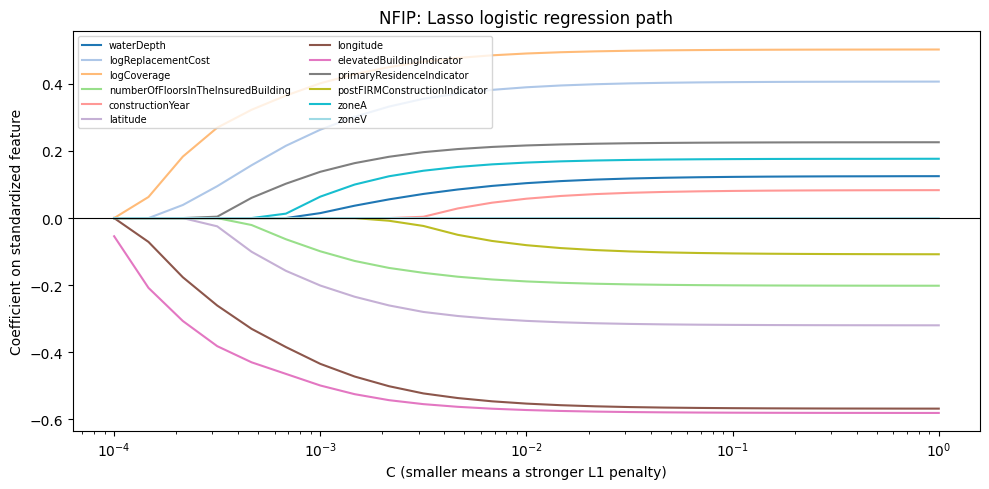

In [6]:
# Lasso path with standardized features: which coefficients survive as the penalty loosens
C_path = np.logspace(-4, 0, 25)
scaled = StandardScaler().fit(train[log_features])
X_tr = scaled.transform(train[log_features])
path = np.array([LogisticRegression(C=c, l1_ratio=1, solver='saga', max_iter=5000).fit(X_tr, y_train).coef_[0]
                 for c in C_path])

fig, ax = plt.subplots(figsize=(10, 5))
colors = plt.cm.tab20(np.linspace(0, 1, len(log_features)))
for j, name in enumerate(log_features):
    ax.semilogx(C_path, path[:, j], label=name, color=colors[j])
ax.axhline(0, color='black', linewidth=0.8)
ax.set_xlabel('C (smaller means a stronger L1 penalty)')
ax.set_ylabel('Coefficient on standardized feature')
ax.set_title('NFIP: Lasso logistic regression path')
ax.legend(fontsize=7, ncol=2, loc='upper left')
plt.tight_layout()
plt.show()

With standardized features, Lasso at C = 0.001 keeps 9 of the 12 features and still reaches a test ROC-AUC of 0.774. Robust scaling is similar, keeping 8 features at 0.770. With min-max scaling Lasso keeps only two, the elevated building and primary residence indicators, and ROC-AUC falls to 0.632. Both survivors are 0/1 features, which are the ones min-max leaves at full width. The penalty picked features by the units they ended up in, not by how useful they are.

The path plot shows the standardized version across the whole range of penalties. Reading from left to right, the elevated building indicator, longitude, and log coverage enter first, and the post-FIRM indicator and construction year enter last. Raw water depth enters late and stays small, around 0.12 per standard deviation even with almost no penalty. That looked odd to me, since depth is the most direct measure of how bad the flooding was. The outlier section below explains it.

### Multicollinearity

The lesson points out that logistic regression has the same problem with correlated features as linear regression. If two features carry nearly the same information, the data cannot tell $2X_1 - X_2$ apart from $1000X_1 - 999X_2$, so the individual coefficients become unstable even when the predictions are fine. I check this two ways, with variance inflation factors (VIFs) and by refitting the model with one of the two cost features removed.

In [7]:
Z = StandardScaler().fit_transform(data[log_features])
vif = pd.Series(np.diag(np.linalg.inv(np.corrcoef(Z, rowvar=False))), index=log_features).round(2)
print('Variance inflation factors (1 = no overlap with the other features):')
print(vif.sort_values(ascending=False).to_string())
print()
print('Correlation, log replacement cost vs. log coverage:',
      round(data['logReplacementCost'].corr(data['logCoverage']), 3))
print('Correlation, construction year vs. post-FIRM indicator:',
      round(data['constructionYear'].corr(data['postFIRMConstructionIndicator']), 3))
print('Share of policies at the $250,000 coverage cap:',
      round((data['totalBuildingInsuranceCoverage'] >= 250000).mean(), 3))
print()

rows = []
for label, cols in [('Both cost features', log_features),
                    ('Drop log coverage', [f for f in log_features if f != 'logCoverage']),
                    ('Drop log replacement cost', [f for f in log_features if f != 'logReplacementCost'])]:
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(train[cols], y_train)
    coefs = dict(zip(cols, model[-1].coef_[0]))
    rows.append({'Model': label,
                 'Coef: log replacement cost': coefs.get('logReplacementCost', np.nan),
                 'Coef: log coverage': coefs.get('logCoverage', np.nan),
                 'Test ROC-AUC': roc_auc_score(y_test, model.decision_function(test[cols]))})
pd.DataFrame(rows).round(3)

Variance inflation factors (1 = no overlap with the other features):
constructionYear                      2.36
postFIRMConstructionIndicator         2.35
logReplacementCost                    1.25
logCoverage                           1.24
elevatedBuildingIndicator             1.20
longitude                             1.20
zoneA                                 1.16
numberOfFloorsInTheInsuredBuilding    1.15
latitude                              1.14
zoneV                                 1.07
primaryResidenceIndicator             1.06
waterDepth                            1.00

Correlation, log replacement cost vs. log coverage: 0.401
Correlation, construction year vs. post-FIRM indicator: 0.75
Share of policies at the $250,000 coverage cap: 0.572



,Model,Coef: log replacement cost,Coef: log coverage,Test ROC-AUC
0,Both cost features,0.407,0.502,0.779
1,Drop log coverage,0.708,NaN,0.776
2,Drop log replacement cost,NaN,0.683,0.762


The overlap in this feature set is mild. The largest VIFs belong to construction year (2.36) and the post-FIRM indicator (2.35), which makes sense because the two have a correlation of 0.75. Buildings put up after a community's first flood map are mostly the newer ones. Everything else is at 1.25 or below, well under the usual warning level of 5 to 10.

Even so, the coefficients move. With both cost features in the model, log replacement cost gets 0.407 and log coverage gets 0.502. Drop coverage and the replacement cost coefficient jumps to 0.708, because it picks up the part of coverage it was correlated with. Test ROC-AUC barely changes (0.779 to 0.776). That is the lesson's point in practice. Correlated features hurt the interpretation of individual coefficients far more than they hurt prediction. The two cost features are only correlated at 0.40, partly because 57% of policies carry $250,000 or more of building coverage, the most a residential policy can have, so coverage stops tracking replacement cost once a house is worth more than that.

### The logistic curve, cross-entropy, and outliers

The next cell takes the standardized model and plots the LINEXP value of each test claim against the logistic curve, along with the observed share of large claims in each LINEXP bin. It also lists the claims with the most extreme LINEXP values and their cross-entropy loss. For a single claim that loss is $-\log(\hat p)$ when the claim was large and $-\log(1 - \hat p)$ when it was not, where $\hat p$ is the predicted probability of a large claim.

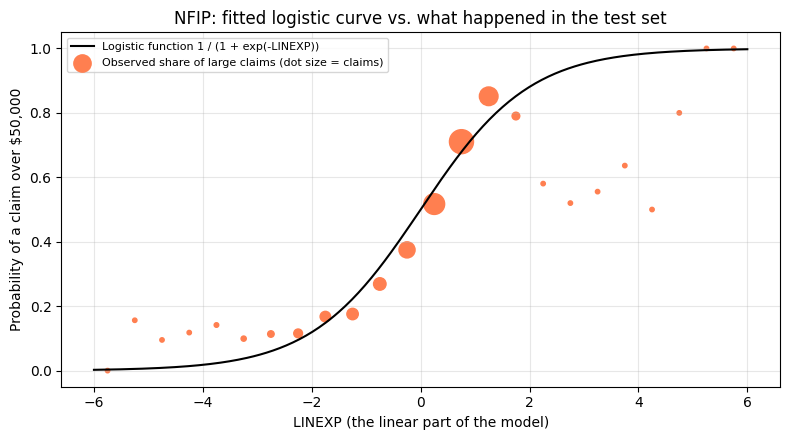

Test claims with the most extreme LINEXP values:
 waterDepth  LINEXP  predicted prob  was large  cross-entropy
        1.0 -12.199             0.0          0          0.000
        4.0  -9.342             0.0          0          0.000
        2.0  -9.295             0.0          0          0.000
        2.0  -8.467             0.0          1          8.467
        1.0  -8.411             0.0          0          0.000
        1.0  -8.236             0.0          0          0.000

Test claims with LINEXP above 2: 270. Predicted share large: 0.921, observed share large: 0.585
Median recorded water depth for those claims: 1.0 | for all test claims: 1.0
Share of total test cross-entropy from the 0.1% of claims with the largest loss: 0.01


In [8]:
baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(train[log_features], y_train)
linexp = baseline.decision_function(test[log_features])
prob = 1 / (1 + np.exp(-linexp))

bins = pd.cut(linexp, np.arange(-6, 6.5, 0.5))
observed = pd.Series(y_test).groupby(bins, observed=True).agg(['mean', 'size'])
centers = [b.mid for b in observed.index]

fig, ax = plt.subplots(figsize=(8, 4.5))
grid_x = np.linspace(-6, 6, 300)
ax.plot(grid_x, 1 / (1 + np.exp(-grid_x)), color='black', label='Logistic function 1 / (1 + exp(-LINEXP))')
ax.scatter(centers, observed['mean'], s=np.clip(observed['size'] / 20, 10, 300), color='coral',
           label='Observed share of large claims (dot size = claims)')
ax.set_xlabel('LINEXP (the linear part of the model)')
ax.set_ylabel('Probability of a claim over $50,000')
ax.set_title('NFIP: fitted logistic curve vs. what happened in the test set')
ax.legend(loc='upper left', fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Written with logaddexp so extreme LINEXP values do not round to log(0)
per_claim_loss = np.logaddexp(0, -(2 * y_test - 1) * linexp)
extreme = pd.DataFrame({'waterDepth': test['waterDepth'].values, 'LINEXP': linexp,
                        'predicted prob': prob, 'was large': y_test, 'cross-entropy': per_claim_loss})
print('Test claims with the most extreme LINEXP values:')
print(extreme.reindex(extreme['LINEXP'].abs().sort_values(ascending=False).index).head(6).round(3).to_string(index=False))
print()
high = linexp > 2
print(f'Test claims with LINEXP above 2: {high.sum():,}. Predicted share large: {prob[high].mean():.3f}, '
      f'observed share large: {y_test[high].mean():.3f}')
print('Median recorded water depth for those claims:', np.median(test['waterDepth'].values[high]),
      '| for all test claims:', np.median(test['waterDepth']))
print('Share of total test cross-entropy from the 0.1% of claims with the largest loss:',
      round(np.sort(per_claim_loss)[-len(per_claim_loss) // 1000:].sum() / per_claim_loss.sum(), 3))

                      Depth handling  Test log loss  Test ROC-AUC
                   Raw depth, linear         0.5770        0.7790
          Depth capped at 15, linear         0.5568        0.7989
Depth capped at 15, spline (6 knots)         0.5395        0.8090

Raw depth, linear: change in log-odds per unit of depth = 0.0102, odds ratio per unit = 1.010
Depth capped at 15, linear: change in log-odds per unit of depth = 0.2063, odds ratio per unit = 1.229


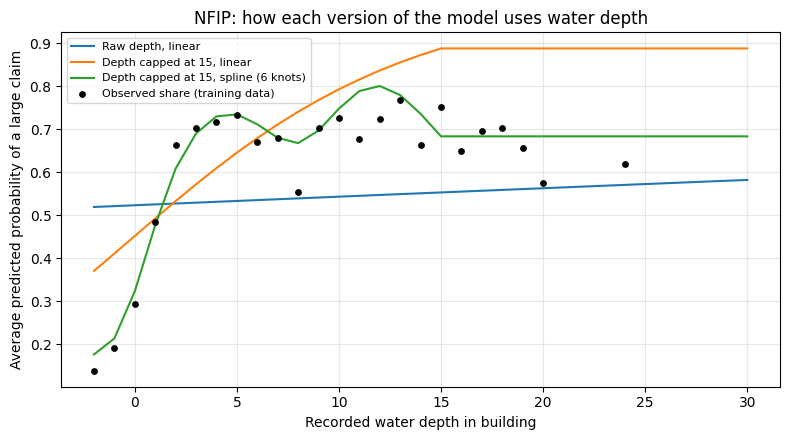

In [9]:
def depth_model(depth_step):
    return Pipeline([('prep', ColumnTransformer([('depth', depth_step[1], [depth_step[0]]),
                                                 ('cont', StandardScaler(), continuous),
                                                 ('bin', 'passthrough', binary)])),
                     ('lr', LogisticRegression(max_iter=3000))])

variants = {
    'Raw depth, linear': depth_model(('waterDepth', StandardScaler())),
    'Depth capped at 15, linear': depth_model(('depthClipped', StandardScaler())),
    'Depth capped at 15, spline (6 knots)': depth_model(('depthClipped', SplineTransformer(n_knots=6, degree=3))),
}
rows = []
for name, model in variants.items():
    model.fit(train, y_train)
    p = model.predict_proba(test)[:, 1]
    rows.append({'Depth handling': name, 'Test log loss': log_loss(y_test, p), 'Test ROC-AUC': roc_auc_score(y_test, p)})
print(pd.DataFrame(rows).round(4).to_string(index=False))
print()
for name in ['Raw depth, linear', 'Depth capped at 15, linear']:
    m = variants[name]
    slope = m.named_steps['lr'].coef_[0][0] / m.named_steps['prep'].named_transformers_['depth'].scale_[0]
    print(f'{name}: change in log-odds per unit of depth = {slope:.4f}, odds ratio per unit = {np.exp(slope):.3f}')

# Average prediction over 3,000 real training claims at each depth (a partial dependence curve),
# so the curves can be compared with the observed shares
sample = train.sample(3000, random_state=0).copy()
depths = np.arange(-2, 31)
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, model in variants.items():
    avg = []
    for dval in depths:
        sample['waterDepth'] = dval
        sample['depthClipped'] = np.clip(dval, -2, 15)
        avg.append(model.predict_proba(sample)[:, 1].mean())
    ax.plot(depths, avg, label=name)
depth_rate = train.groupby(train['waterDepth'].round())['largeClaim'].agg(['mean', 'size'])
depth_rate = depth_rate[(depth_rate['size'] >= 50) & depth_rate.index.isin(depths)]
ax.scatter(depth_rate.index, depth_rate['mean'], color='black', s=15, zorder=3, label='Observed share (training data)')
ax.set_xlabel('Recorded water depth in building')
ax.set_ylabel('Average predicted probability of a large claim')
ax.set_title('NFIP: how each version of the model uses water depth')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

The large dots in the middle of the plot sit close to the curve, so for most claims the predicted probabilities are about right. The tails are a different story. Below a LINEXP of about -2.5 the observed share of large claims levels off around 10% to 15% while the curve heads toward zero, and above 2 the model is far too confident. The 270 test claims with LINEXP above 2 get an average predicted probability of 0.921, but only 58.5% of them were large.

The extreme-value table shows the outlier problem from the lesson. The fourth claim in the table has a LINEXP of -8.467, so the model gave it almost no chance of being large, but it was. Its cross-entropy loss is 8.467, the same number as the LINEXP. Once LINEXP is far from zero, $-\log(\hat p)$ grows in a straight line with it, so the log does nothing to soften a confident mistake. That is the lesson's LINEXP = -1000 example on a smaller scale. In this data those cases are rare. The 0.1% of test claims with the largest loss account for only about 1% of the total, so they are not what drives the fit.

Outliers in the features turned out to be the bigger problem, and water depth shows it. With raw depth, the model estimates that each extra unit of depth raises the log-odds of a large claim by only 0.0102. With depth capped at 15 the estimate becomes 0.2063 per unit, about 20 times larger. The 99 claims with recorded depths above 100 have a lower share of large claims (42%) than the data as a whole, and because LINEXP is linear in depth, the only way to fit them is to flatten the slope for everyone else. Capping depth raises test ROC-AUC from 0.779 to 0.799.

Replacing the straight line with a spline (a smooth curve built from six knots) raises it again to 0.809, and the plot shows why. The observed share of large claims climbs steeply from about 14% at a depth of -2 to about 73% at 5 and then stays roughly flat. The raw-depth model is almost a flat line across that whole range, and the capped linear model keeps climbing to nearly 0.89 at 15, well past where the data levels off. The spline follows the observed points closely.

### Tuning the penalty

The lesson's loss for regularized logistic regression is cross-entropy plus $\lambda$ times the sum of the absolute coefficients (Lasso), and the same idea works with squared coefficients (Ridge) or a mix of the two (elastic net). I tuned both the strength and the mix with 5-fold cross-validation on the training set, using the spline-depth model. The grid covers C from 0.0003 to 10 and `l1_ratio` values of 0 (Ridge), 0.5 (elastic net), and 1 (Lasso). The scoring metric is log loss, which is the same cross-entropy the model minimizes, so the tuning rewards probabilities that are well calibrated and not only on the right side of 0.5.

Grid search took 80 seconds
Best settings: {'lr__C': 10, 'lr__l1_ratio': 1, 'lr__solver': 'saga'} | CV log loss: 0.5381


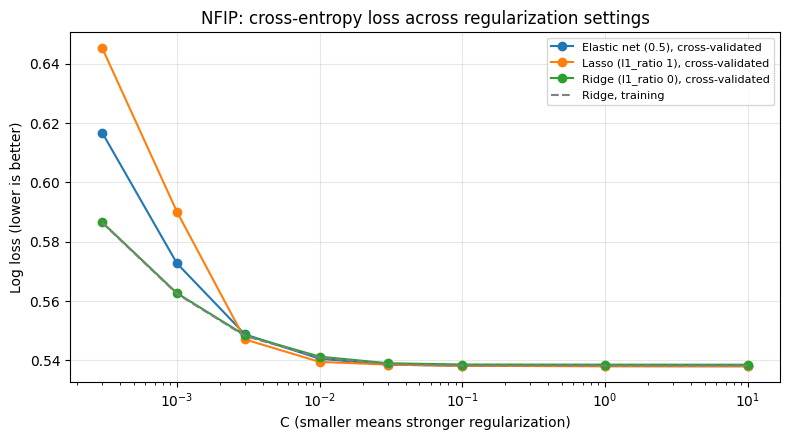

penalty mix  Elastic net (0.5)  Lasso (l1_ratio 1)  Ridge (l1_ratio 0)
param_lr__C                                                           
0.0003                  0.6167              0.6453              0.5866
0.0010                  0.5728              0.5901              0.5627
0.0030                  0.5488              0.5471              0.5485
0.0100                  0.5406              0.5395              0.5413
0.0300                  0.5386              0.5386              0.5391
0.1000                  0.5382              0.5382              0.5386
1.0000                  0.5381              0.5381              0.5386
10.0000                 0.5381              0.5381              0.5386


In [10]:
C_values = [0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 1, 10]
pipe = depth_model(('depthClipped', SplineTransformer(n_knots=6, degree=3)))
pipe.set_params(lr__tol=1e-3)
param_grid = [{'lr__C': C_values, 'lr__l1_ratio': [0], 'lr__solver': ['lbfgs']},
              {'lr__C': C_values, 'lr__l1_ratio': [0.5, 1], 'lr__solver': ['saga']}]
t0 = time.time()
search = GridSearchCV(pipe, param_grid, scoring='neg_log_loss', cv=5, n_jobs=-1, return_train_score=True)
search.fit(train, y_train)
print(f'Grid search took {time.time() - t0:.0f} seconds')
print('Best settings:', search.best_params_, '| CV log loss:', round(-search.best_score_, 4))

cv = pd.DataFrame(search.cv_results_)
cv['penalty mix'] = cv['param_lr__l1_ratio'].map({0: 'Ridge (l1_ratio 0)', 0.5: 'Elastic net (0.5)', 1: 'Lasso (l1_ratio 1)'})
fig, ax = plt.subplots(figsize=(8, 4.5))
for mix, part in cv.groupby('penalty mix'):
    part = part.sort_values('param_lr__C')
    ax.semilogx(part['param_lr__C'].astype(float), -part['mean_test_score'], marker='o', label=mix + ', cross-validated')
ridge = cv[cv['param_lr__l1_ratio'] == 0].sort_values('param_lr__C')
ax.semilogx(ridge['param_lr__C'].astype(float), -ridge['mean_train_score'], linestyle='--', color='gray', label='Ridge, training')
ax.set_xlabel('C (smaller means stronger regularization)')
ax.set_ylabel('Log loss (lower is better)')
ax.set_title('NFIP: cross-entropy loss across regularization settings')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(cv.pivot_table(index='param_lr__C', columns='penalty mix', values='mean_test_score').mul(-1).round(4))

### Final evaluation on the held-out test set

Test claims: 25261
                                       Model  Accuracy  Balanced acc.    F1  Log loss  ROC-AUC
     Majority class (predicts the base rate)     0.532          0.500 0.695     0.691    0.500
Logistic regression, standardized, raw depth     0.714          0.706 0.759     0.577    0.779
     Tuned logistic regression, spline depth     0.727          0.722 0.759     0.540    0.809


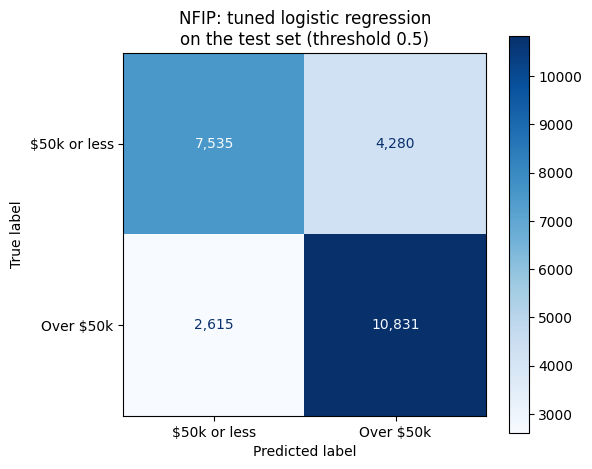

In [11]:
final = search.best_estimator_
p_final = final.predict_proba(test)[:, 1]
p_base = baseline.predict_proba(test[log_features])[:, 1]
p_majority = np.full(len(y_test), y_train.mean())
results = pd.DataFrame([scores('Majority class (predicts the base rate)', y_test, p_majority),
                        scores('Logistic regression, standardized, raw depth', y_test, p_base),
                        scores('Tuned logistic regression, spline depth', y_test, p_final)])
print('Test claims:', len(y_test))
print(results.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, (p_final >= 0.5).astype(int), display_labels=['$50k or less', 'Over $50k'],
                                        cmap='Blues', values_format=',', ax=ax)
ax.set_title('NFIP: tuned logistic regression\non the test set (threshold 0.5)')
plt.tight_layout()
plt.show()

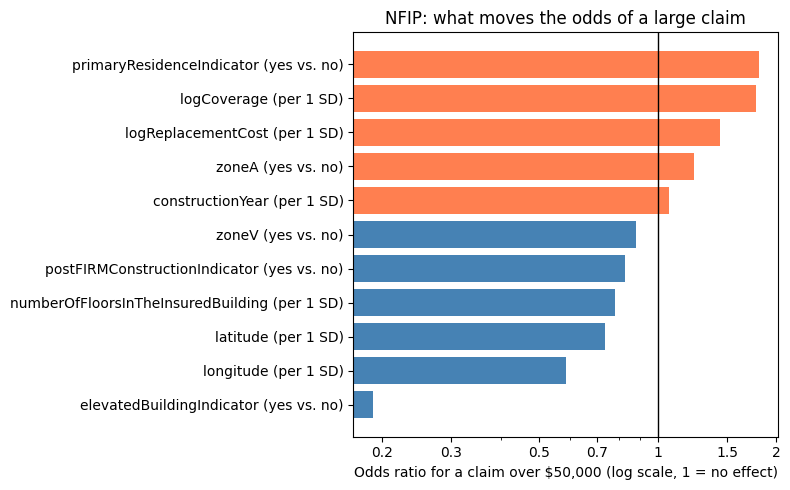

elevatedBuildingIndicator             0.189
longitude                             0.585
latitude                              0.735
numberOfFloorsInTheInsuredBuilding    0.780
postFIRMConstructionIndicator         0.824
zoneV                                 0.882
constructionYear                      1.070
zoneA                                 1.240
logReplacementCost                    1.442
logCoverage                           1.779
primaryResidenceIndicator             1.804


In [12]:
# Odds ratios: continuous features per 1 standard deviation, binary features yes vs. no
lr = final.named_steps['lr']
names = final.named_steps['prep'].get_feature_names_out()
coef = pd.Series(lr.coef_[0], index=names)
coef = coef[~coef.index.str.startswith('depth__')]
odds = np.exp(coef).sort_values()
labels = [n.split('__')[1] + (' (per 1 SD)' if n.startswith('cont__') else ' (yes vs. no)') for n in odds.index]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(labels, odds.values, color=np.where(odds.values > 1, 'coral', 'steelblue'))
ax.axvline(1, color='black', linewidth=1)
ax.set_xscale('log')
ticks = [0.2, 0.3, 0.5, 0.7, 1, 1.5, 2]
ax.set_xticks(ticks)
ax.set_xticklabels([str(t) for t in ticks])
ax.set_xlabel('Odds ratio for a claim over $50,000 (log scale, 1 = no effect)')
ax.set_title('NFIP: what moves the odds of a large claim')
plt.tight_layout()
plt.show()
print(odds.round(3).rename(lambda n: n.split('__')[1]).to_string())

### Reading the coefficients as odds ratios

Since LINEXP is the log-odds, $e^{\beta}$ is the factor by which the odds of a large claim change. For the continuous features that is per one standard deviation, and for the indicators it is yes versus no. Water depth is left off the chart because the spline spreads its effect over eight separate terms.

The elevated building indicator has by far the strongest effect, with an odds ratio of 0.189, so an elevated building has about one fifth the odds of a large claim of a similar building that is not elevated. Primary residences (1.80) and higher coverage (1.78 per standard deviation) push the odds up. Coverage works partly as a ceiling here, since a claim cannot pay more than the policy limit. Longitude (0.585) most likely reflects the difference between the 2017 storms, with Harvey in Texas to the west and Irma in Florida to the east, more than anything about longitude itself.

### Are the claims independent?

The lesson's stock example makes the point that logistic regression assumes independent samples. Hundreds of rows that move together are really one example repeated. The 2017 NFIP claims are heavily clustered. Texas and Florida account for 87% of the rows used here, and neighbors on the same street saw the same water.

To measure how much that matters, I grouped claims into location cells of 0.1 degrees of latitude by 0.1 degrees of longitude (roughly 10 km on a side) and bootstrapped the coefficients two ways, once resampling individual claims and once resampling whole cells. If the claims were independent, the two would give about the same spread. The last line refits the tuned model with entire cells held out of training, to check whether prediction suffers when the model has not seen a claim's neighbors.

In [13]:
# Row bootstrap vs. location-cell bootstrap for the coefficient spread
data['locationCell'] = data['latitude'].round(1).astype(str) + '_' + data['longitude'].round(1).astype(str)
boot_cols = ['depthClipped'] + continuous + binary
Xb = StandardScaler().fit_transform(data[boot_cols])
yb = data['largeClaim'].values
cells = data['locationCell'].values
cell_rows = pd.Series(np.arange(len(data))).groupby(cells).apply(np.array)
rng = np.random.RandomState(0)
row_fits, cell_fits = [], []
for _ in range(50):
    idx = rng.randint(0, len(yb), len(yb))
    row_fits.append(LogisticRegression(max_iter=1000).fit(Xb[idx], yb[idx]).coef_[0])
    pick = rng.choice(len(cell_rows), len(cell_rows), replace=True)
    idx = np.concatenate(cell_rows.iloc[pick].values)
    cell_fits.append(LogisticRegression(max_iter=1000).fit(Xb[idx], yb[idx]).coef_[0])
spread = pd.DataFrame({'SD, resampling claims': np.std(row_fits, axis=0),
                       'SD, resampling location cells': np.std(cell_fits, axis=0)}, index=boot_cols)
spread['Ratio'] = spread.iloc[:, 1] / spread.iloc[:, 0]
print('Location cells:', len(cell_rows), '| claims:', len(yb))
print(spread.round(3).to_string())
design_effect = (spread['Ratio'] ** 2).mean()
print()
print(f'Average variance inflation from clustering: {design_effect:.1f}x, '
      f'so {len(yb):,} claims behave like roughly {len(yb) / design_effect:,.0f} independent ones for estimating coefficients')

g_tr, g_te = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=0).split(data, yb, cells))
grouped = depth_model(('depthClipped', SplineTransformer(n_knots=6, degree=3)))
grouped.set_params(**{k: v for k, v in search.best_params_.items()}, lr__tol=1e-3)
grouped.fit(data.iloc[g_tr], yb[g_tr])
print('Tuned model, test ROC-AUC with whole location cells held out:',
      round(roc_auc_score(yb[g_te], grouped.predict_proba(data.iloc[g_te])[:, 1]), 4))

Location cells: 3580 | claims: 101042
                                    SD, resampling claims  SD, resampling location cells  Ratio
depthClipped                                        0.014                          0.064  4.608
logReplacementCost                                  0.024                          0.063  2.562
logCoverage                                         0.018                          0.035  1.894
numberOfFloorsInTheInsuredBuilding                  0.013                          0.034  2.678
constructionYear                                    0.010                          0.057  5.501
latitude                                            0.010                          0.033  3.238
longitude                                           0.011                          0.054  4.850
elevatedBuildingIndicator                           0.010                          0.043  4.259
primaryResidenceIndicator                           0.008                          0.021  2.697
po

Tuned model, test ROC-AUC with whole location cells held out: 0.8169


## Discussion

### Overfitting

Overfitting turned out to be a small risk for this model, and the tuning plot shows why. The tuned logistic regression has 19 coefficients (eight for the depth spline and one for each of the other 11 features), which is very few next to 75,781 training claims. For every penalty mix, cross-validated log loss is flat at 0.538 to 0.539 for any C of 0.03 or larger, and the Ridge training curve sits right on top of the cross-validated one, so there is no gap for regularization to close. The search picked Lasso at C = 10 (CV log loss 0.5381), which is close to no penalty at all. Strong penalties hurt instead. At C = 0.0003, Lasso's cross-validated log loss climbs to 0.645 and Ridge's to 0.587, which is underfitting.

The test set agrees. The tuned model's test log loss is 0.540, right next to its 0.538 cross-validated score. The location-grouped check gives a test ROC-AUC of 0.817 with whole cells held out, so the model does not depend on having seen the neighbors of each test claim.

Where clustering does matter is in how certain the coefficients look. Resampling location cells instead of single claims made the coefficient spread 1.9 to 7.4 times larger, depending on the feature. The average variance inflation is 16.6, so the 101,042 claims carry about as much information about the coefficients as 6,094 independent ones would. Standard errors from the usual formula would make every coefficient look far more certain than it is. With only 50 bootstrap resamples these ratios are rough, but the direction is clear.

### Metrics and hyperparameter tuning

Log loss (cross-entropy) was the tuning metric because it is the quantity logistic regression minimizes and it judges the predicted probabilities directly. The test results add accuracy, balanced accuracy, F1, and ROC-AUC, which are easier to read as decisions. The classes are close to balanced, so accuracy is meaningful here, and always guessing the majority class scores 0.532.

The grid crossed eight values of C, from 0.0003 to 10, with Ridge, elastic net, and Lasso. Lasso at C = 10 won, but every combination with C of at least 0.03 scored between 0.5381 and 0.5391, so the choice barely matters. The mix only matters under strong penalties, where Lasso degrades fastest because it removes whole features while Ridge only shrinks them.

On the test set the tuned model reached 0.727 accuracy, 0.722 balanced accuracy, 0.759 F1, 0.540 log loss, and 0.809 ROC-AUC, compared with 0.714, 0.706, 0.759, 0.577, and 0.779 for the standardized model with raw depth. Nearly all of that gain came from how depth was handled, not from tuning. The confusion matrix shows the tuned model finds 10,831 of the 13,446 large claims (81%) but also flags 4,280 of the 11,815 smaller ones as large. A different threshold could trade those errors off, but I left it at 0.5 since the classes are balanced.

### Expected or unexpected

I expected scaling to change the speed and not much else, since a lightly penalized logistic regression should give nearly the same predictions whatever units the features are in. That held for the well-behaved setups, where standardized, min-max, and robust scaling all scored 0.778 to 0.779 at C = 1. Two things surprised me. The first was the raw unscaled run, which stopped without any warning and still produced a clearly worse model. The second was how much min-max scaling hurt once a strong penalty was added, mostly because one claim in Guam stretched the longitude range. I had thought of min-max scaling and standardization as interchangeable, and with a penalty they are not.

The water depth result was also unexpected. Depth is the most direct measure of flooding, so I expected it to be one of the strongest features from the start. Instead the raw version entered the Lasso path late and barely moved the predictions, and it took the depth plot to see that a few extreme values were flattening its slope by a factor of about 20.

Last, I expected the 2017 claims to be clustered, but not by this much. A variance inflation of 16.6 means most of the apparent sample size comes from repeated neighbors, which is the lesson's stock example on a large scale. The predictions held up when whole areas were held out, but any statement about how certain a coefficient is would need clustered standard errors.

### How EDA helped

EDA shaped this notebook in four places. The Module B work showed that damage amount predicts payout almost perfectly, which is why every damage and payout field is left out. The table of raw scales showed costs spanning several orders of magnitude, with values near a billion dollars, which is why both cost features are log-transformed, and the scaling experiment confirmed that the log transform did more for the model (0.726 to 0.779) than any choice of scaler. Comparing water depth with the observed share of large claims showed a rise and plateau that a straight line cannot follow, which is why depth was capped and fit with a spline. And knowing that most 2017 claims came from two hurricanes is what prompted the independence check, which turned out to be the biggest caveat in the notebook.

The minimum and maximum columns of that same table also explained the min-max result after the fact. Once I saw a longitude of 144.6 in a dataset of mostly Texas and Florida claims, it was clear why one scaler squeezed longitude so badly.

### External sources

- scikit-learn User Guide, "Logistic regression" (in the Linear Models chapter): https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
- scikit-learn example, "Importance of Feature Scaling," which compares models trained with and without standardization: https://scikit-learn.org/stable/auto_examples/preprocessing/plot_scaling_importance.html
- scikit-learn User Guide, "Preprocessing data," covering standardization, min-max scaling, robust scaling, and spline features: https://scikit-learn.org/stable/modules/preprocessing.html
- James, Witten, Hastie, and Tibshirani, *An Introduction to Statistical Learning*, Chapter 4 ("Classification"), the section on logistic regression.
- Cameron and Miller, "A Practitioner's Guide to Cluster-Robust Inference," *Journal of Human Resources* 50(2), 2015, on why clustered data makes ordinary standard errors too small.


### Conclusions

Using only building, policy, and flood characteristics, a tuned logistic regression separates 2017 NFIP claims over $50,000 from smaller ones with a test ROC-AUC of 0.809 and 73% accuracy, compared with 53% for always guessing the majority class. Most of the work was in preparing the features, not tuning the model. Log-transforming the costs, standardizing before applying a penalty, and capping and smoothing water depth each mattered more than the choice of C or penalty mix, which barely moved the cross-validated loss.

Each of the lesson's warnings showed up in this data. Unscaled features slowed the solver down or quietly stopped it short, min-max scaling made the penalty unfair in the same way as the milk and steak example, outliers in depth flattened its slope about 20-fold, correlated cost features traded weight between them, and clustering by location means the claims are far less independent than the row count suggests. For the Capstone, logistic regression is a useful baseline for claim severity because its odds ratios are easy to explain, as long as the coefficients are reported with clustered uncertainty and depth is modeled as a curve instead of a line.